In [51]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D
import numpy as np

## Evaluation of Data without augmentation

In [52]:
data = pd.read_csv("../example_dataset.csv")
testing_data = pd.read_csv("../example_testing_dataset.csv")

classes_dict = {"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
data["steel_class"] = [classes_dict[c] for c in data["steel_class"] ]    
testing_data["steel_class"] = [classes_dict[c] for c in testing_data["steel_class"] ]    

# make data numeric
for column in data.columns:
        for index, value in data[column].items():
            if isinstance(value, str):
                data.at[index, column] = value.replace(",", ".")

for column in testing_data.columns:
        for index, value in testing_data[column].items():
            if isinstance(value, str):
                testing_data.at[index, column] = value.replace(",", ".")
                
data = data.map(pd.to_numeric)
testing_data = testing_data.map(pd.to_numeric)

Group Name: St 48
(10, 10)
Group Name: St 37
(20, 10)
Group Name: St Si
(10, 10)
Group Name: St 48-TH
(60, 10)
Group Name: Puddelstahl
(20, 10)


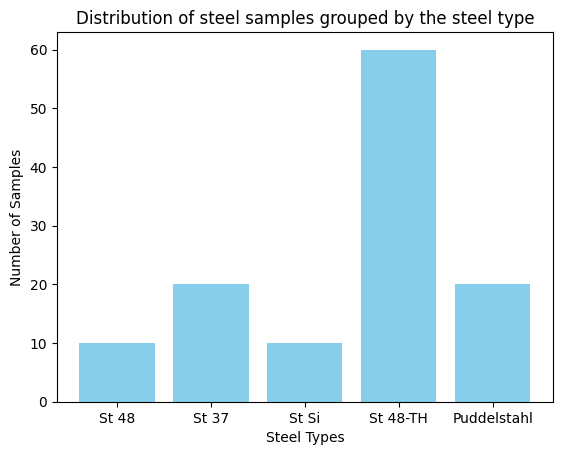

In [53]:
grouped_data = data.groupby("steel_class")
number_of_samples_group = []

for group_id, gdata in grouped_data:
    for key, val in classes_dict.items():
        if val == group_id:
            group_name = key
    print("Group Name:", group_name)
    print(gdata.shape)
    number_of_samples_group.append(gdata.shape[0])

steel_type_names = classes_dict.keys()

plt.bar(steel_type_names, number_of_samples_group, color='skyblue')

plt.xlabel('Steel Types')
plt.ylabel('Number of Samples')
plt.title('Distribution of steel samples grouped by the steel type')

plt.savefig('example_distribution_samples_steeltypes.jpg', format='jpg')
plt.show()

In [54]:
# create X and y
X = data.drop(columns="steel_class")
y = data["steel_class"]

In [55]:
XGB_model = xgb.XGBClassifier(objective="multi:softmax", num_class=5, n_estimators=100, max_depth=3, learning_rate=1, gamma=0.1, reg_lambda=20)
XGB_model.fit(X, y)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=0.1, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None, num_class=5,
              num_parallel_tree=None, ...)

In [56]:
X_testing_data = testing_data.iloc[:,:-1]
y_testing_data = testing_data.iloc[:,-1]
predictions = XGB_model.predict(X_testing_data)
predictions

array([2, 2, 2, ..., 4, 4, 4])

In [57]:
count_correct = 0
for i in range(len(predictions)):
    if predictions[i] == y_testing_data[i]:
        count_correct += 1
print(count_correct / X_testing_data.shape[0])

0.8258212375859435


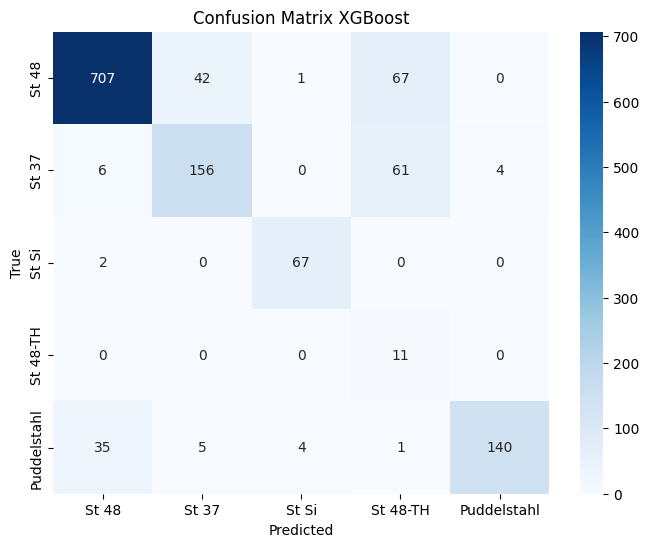

In [58]:
# build Confusion Matrix
conf_matrix = confusion_matrix(y_testing_data, predictions)
{"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
# print Confusion Martix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"], yticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix XGBoost')
plt.savefig('Pre_Augment_Confusion_Matrix_XGBoost.jpg', format='jpg')

plt.show()

In [59]:
new_labels = ["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"]

report = classification_report(y_testing_data, predictions, target_names=new_labels)

print(report)

              precision    recall  f1-score   support

       St 48       0.94      0.87      0.90       817
       St 37       0.77      0.69      0.73       227
       St Si       0.93      0.97      0.95        69
    St 48-TH       0.08      1.00      0.15        11
 Puddelstahl       0.97      0.76      0.85       185

    accuracy                           0.83      1309
   macro avg       0.74      0.86      0.72      1309
weighted avg       0.91      0.83      0.86      1309



<br>

## Evaluation of Data with augmentation 

In [60]:
data = pd.read_csv("../example_dataset.csv_with_augmented_data_SMOTE_ENN.csv")
#data = pd.read_csv("../example_dataset.csv_with_augmented_data_WGANs.csv")

testing_data = pd.read_csv("../example_testing_dataset.csv")

classes_dict = {"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
data["steel_class"] = [classes_dict[c] for c in data["steel_class"] ]    
testing_data["steel_class"] = [classes_dict[c] for c in testing_data["steel_class"] ]    

# make data numeric
for column in data.columns:
        for index, value in data[column].items():
            if isinstance(value, str):
                data.at[index, column] = value.replace(",", ".")

for column in testing_data.columns:
        for index, value in testing_data[column].items():
            if isinstance(value, str):
                testing_data.at[index, column] = value.replace(",", ".")
                
data = data.map(pd.to_numeric)
testing_data = testing_data.map(pd.to_numeric)

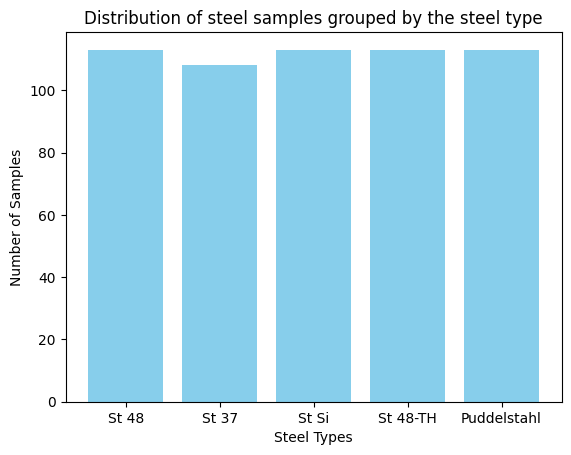

In [61]:
grouped_data = data.groupby("steel_class")
number_of_samples_group = []

for group_id, gdata in grouped_data:
    for key, val in classes_dict.items():
        if val == group_id:
            group_name = key
    number_of_samples_group.append(gdata.shape[0])


steel_type_names = classes_dict.keys()

plt.bar(steel_type_names, number_of_samples_group, color='skyblue')

plt.xlabel('Steel Types')
plt.ylabel('Number of Samples')
plt.title('Distribution of steel samples grouped by the steel type')

plt.show()

In [62]:
# create X and y
X = data.drop(columns="steel_class")
y = data["steel_class"]
XGB_model_aug = xgb.XGBClassifier(objective="multi:softmax", num_class=5, n_estimators=100, max_depth=3, learning_rate=1, gamma=0.1, reg_lambda=20)
XGB_model_aug.fit(X, y)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=0.1, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None, num_class=5,
              num_parallel_tree=None, ...)

In [63]:
predictions_augmented = XGB_model_aug.predict(X_testing_data)
predictions_augmented

array([2, 2, 2, ..., 4, 4, 4])

In [64]:
count_correct = 0
for i in range(len(predictions_augmented)):
    if predictions_augmented[i] == y_testing_data[i]:
        count_correct += 1
print(count_correct / X_testing_data.shape[0])

0.919022154316272


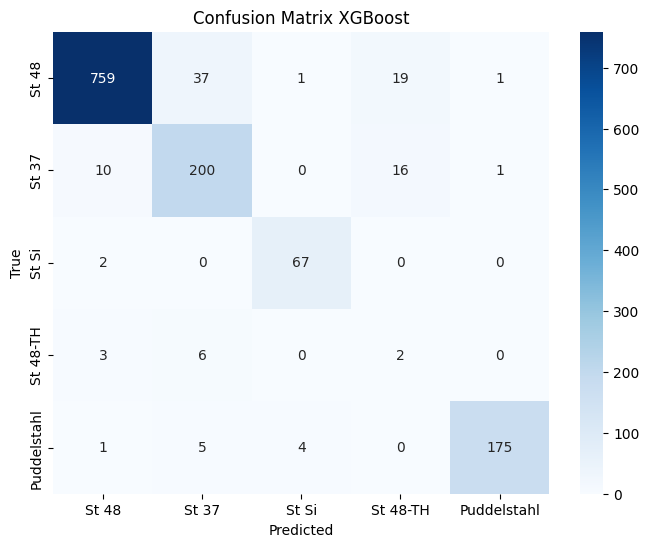

In [65]:
# build Confusion Matrix
conf_matrix = confusion_matrix(y_testing_data, predictions_augmented)
{"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
# print Confusion Martix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"], yticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix XGBoost')
plt.savefig('SMOTE_ENN_Post_augment_Confusion_Matrix_XGBoost.jpg', format='jpg')

plt.show()

In [66]:
new_labels = ["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"]

report = classification_report(y_testing_data, predictions_augmented, target_names=new_labels)

print(report)

              precision    recall  f1-score   support

       St 48       0.98      0.93      0.95       817
       St 37       0.81      0.88      0.84       227
       St Si       0.93      0.97      0.95        69
    St 48-TH       0.05      0.18      0.08        11
 Puddelstahl       0.99      0.95      0.97       185

    accuracy                           0.92      1309
   macro avg       0.75      0.78      0.76      1309
weighted avg       0.94      0.92      0.93      1309

